In [8]:
a= 1
b=2
c=a+b

In [9]:
print (c)

3


In [10]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product


In [11]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa_1 = [3, 5, 7]
larguras_caixa_1 = [2, 4, 6]

comprimentos_caixa_2 = [2, 4, 7]
larguras_caixa_2 = [2, 3, 5]

In [12]:
indice = 0 # seleciona o tamanho do palete e da caixa de acordo com o indice
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento_1 = comprimentos_caixa_1[indice]
caixa_largura_1 = larguras_caixa_1[indice]

caixa_comprimento_2 = comprimentos_caixa_2[indice]
caixa_largura_2 = larguras_caixa_2[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões da caixa 1: {caixa_comprimento_1}x{caixa_largura_1}")
print(f"Dimensões da caixa 2: {caixa_comprimento_2}x{caixa_largura_2}")



Dimensões do palete: 8x6
Dimensões da caixa 1: 3x2
Dimensões da caixa 2: 2x2


In [13]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse=True)
print(f"Dimensoes classificadas do palete: {L}x{W}")

Dimensoes classificadas do palete: 8x6


In [14]:
dimensoes_caixa_1 = [caixa_comprimento_1,caixa_largura_1]
l_um, w_um = sorted(dimensoes_caixa_1, reverse=True)
print(f"Dimensoes classificadas da caixa: {l_um}x{w_um}")

Dimensoes classificadas da caixa: 3x2


In [15]:
l_dois, w_dois = dimensoes_caixa_1[::-1]
print(f"Dimensões classificadas da caxa em pé: {l_dois}x{w_dois}")

Dimensões classificadas da caxa em pé: 2x3


In [16]:
dimensoes_caixa_2 = [caixa_comprimento_2,caixa_largura_2]
l_um_2, w_um_2 = sorted(dimensoes_caixa_2, reverse=True)
print(f"Dimensoes classificadas da caixa: {l_um_2}x{w_um_2}")

Dimensoes classificadas da caixa: 2x2


In [17]:
l_dois_2, w_dois_2 = dimensoes_caixa_2[::-1]
print(f"Dimensões classificadas da caxa em pé: {l_dois_2}x{w_dois_2}")

Dimensões classificadas da caxa em pé: 2x2


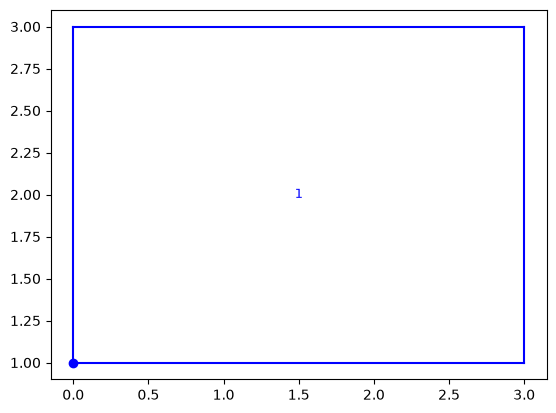

In [18]:
def plotar_caixa_1(bottom_left: list, 
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l ], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha="center", va="center")
plotar_caixa_1(bottom_left=[0, 1], l=3, w=2, color="blue", label="1")

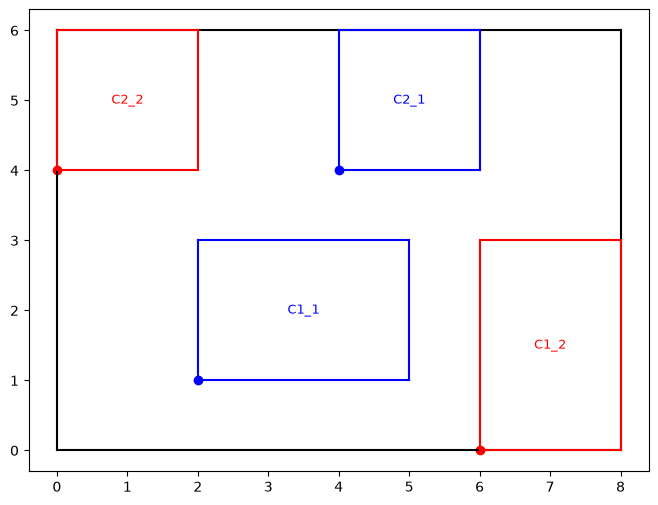

In [19]:
def plotar_caixa_1(bottom_left: list, 
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l ], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha="center", va="center")


def plotar_caixa_2(bottom_left: list, 
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l ], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha="center", va="center")

def plotar_palete(L: int, W: int):
    plt.figure(figsize=(8, 6))
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")
plotar_palete(L, W)
plotar_caixa_1(bottom_left=[2, 1], l=3, w=2, color="blue", label="C1_1")
plotar_caixa_1(bottom_left=[6, 0], l=2, w=3, color="red", label="C1_2")
plotar_caixa_2(bottom_left=[4, 4], l=2, w=2, color="blue", label="C2_1")
plotar_caixa_2(bottom_left=[0, 4], l=2, w=2, color="red", label="C2_2")

In [20]:
f_um = lambda n_um, l_um, n_dois, l_dois, n_um_2, l_um_2, n_dois_2, l_dois_2: \
    n_um * l_um + n_dois * l_dois + n_um_2 * l_um_2 + n_dois_2 * l_dois_2

f_dois = lambda n_um, w_um, n_dois, w_dois: \
    n_um * w_um + n_dois * w_dois


f_um_2 = lambda n_um, l_um_2, n_dois, l_dois_2: \
    n_um * l_um_2 + n_dois * l_dois_2

f_dois_2 = lambda n_um, w_um_2, n_dois, w_dois_2: \
    n_um * w_um_2 + n_dois * w_dois_2



In [21]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2, n_um_2=1, l_um_2=2, n_dois_2=1, l_dois_2=2))     # p <= L - w_um
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3))   # q <= W - w_um

11
4


C:\Users\marce\AppData\Local\Temp\ipykernel_15048\1712621736.py:29: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8, 6))


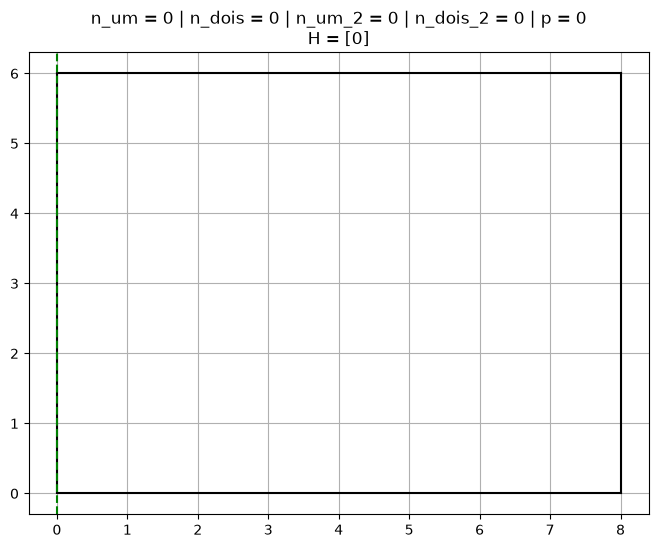

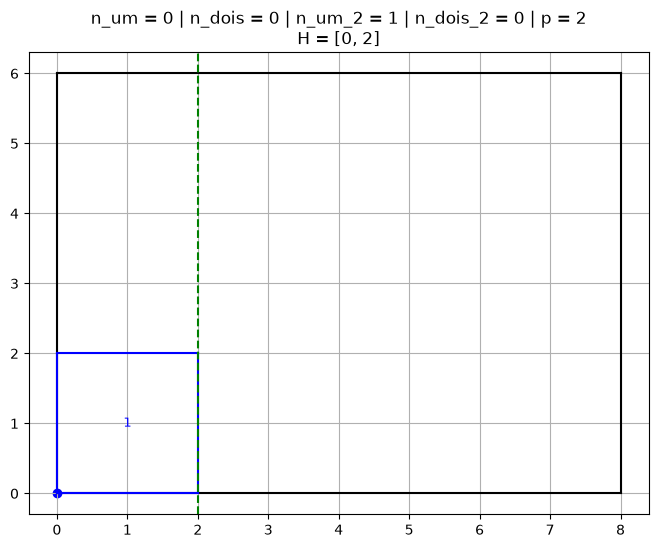

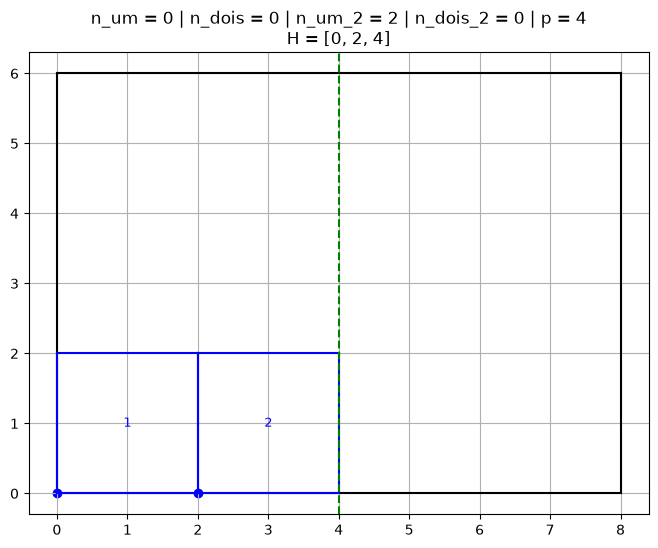

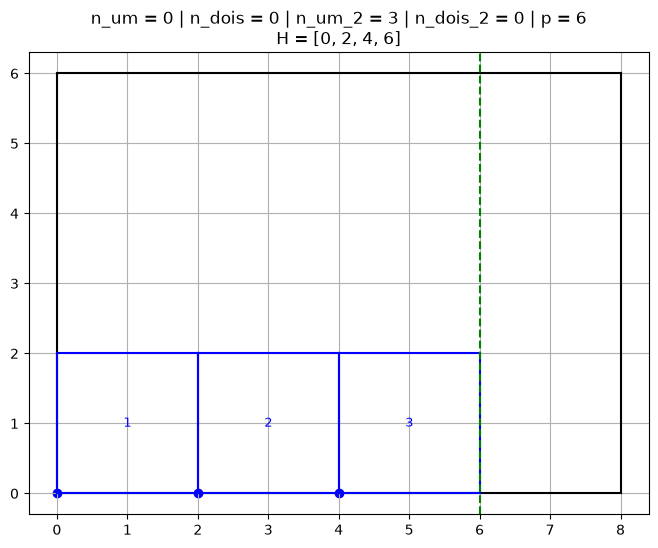

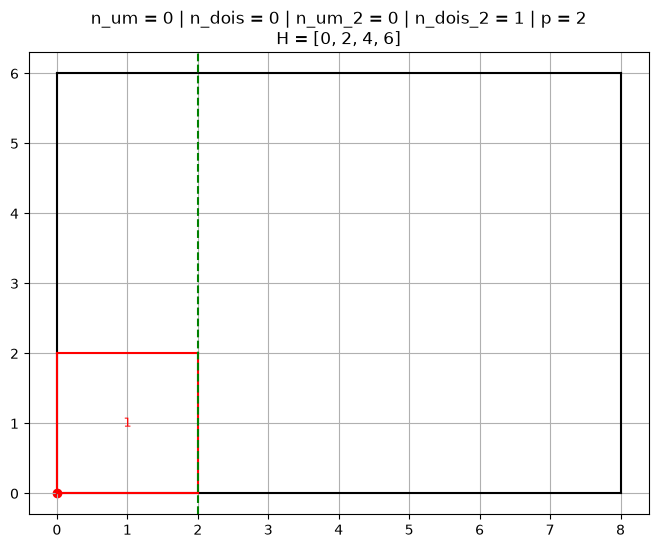

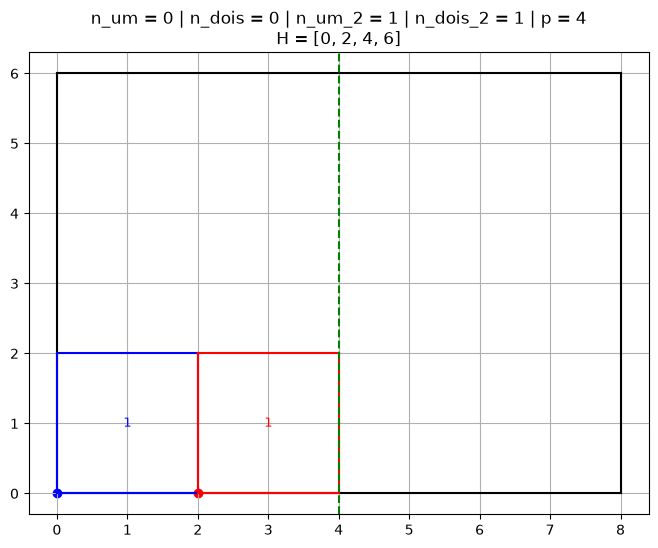

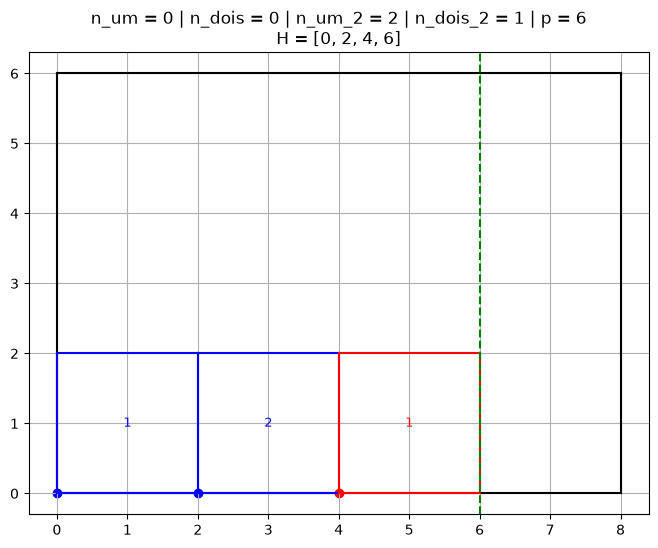

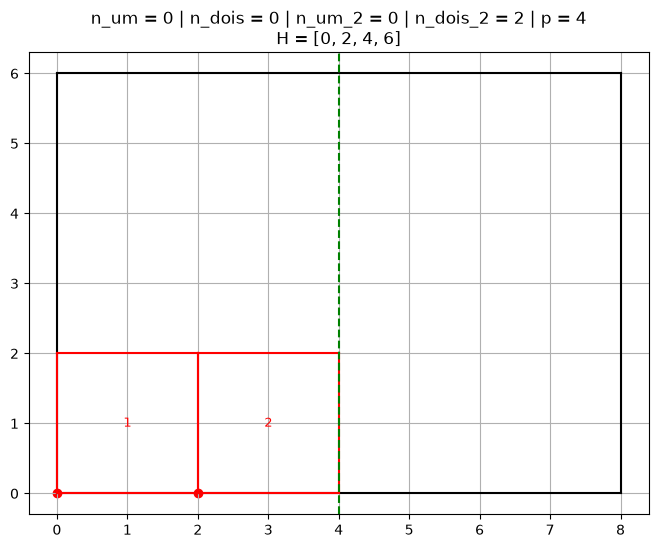

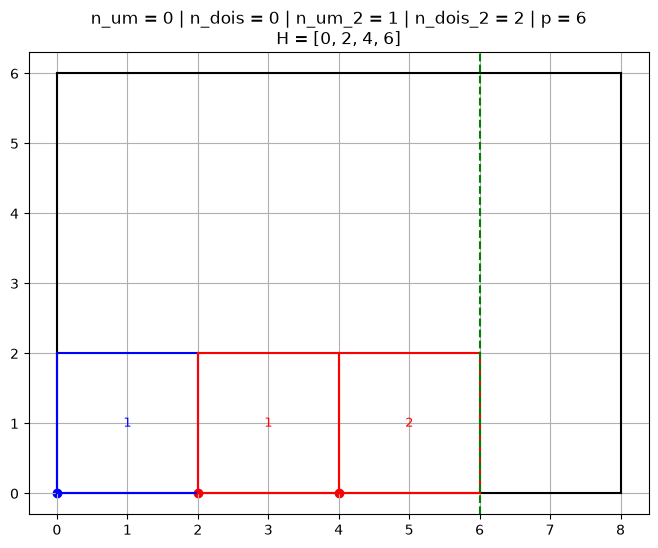

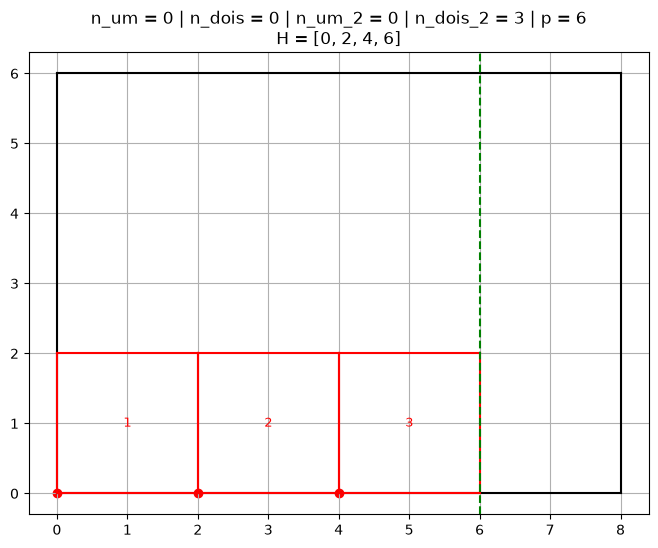

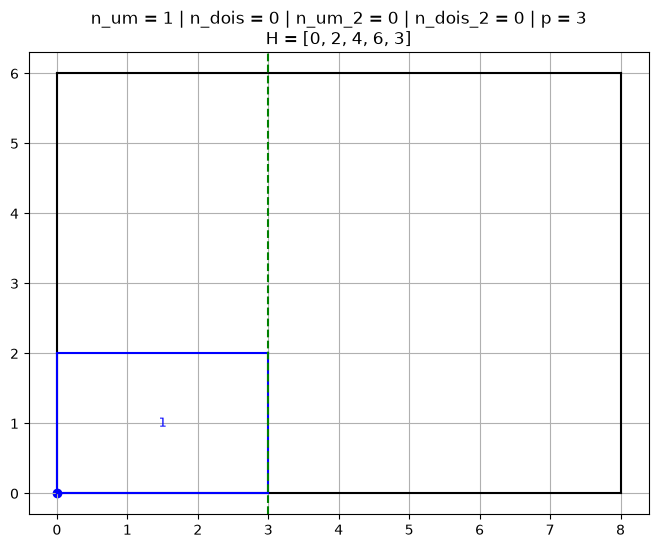

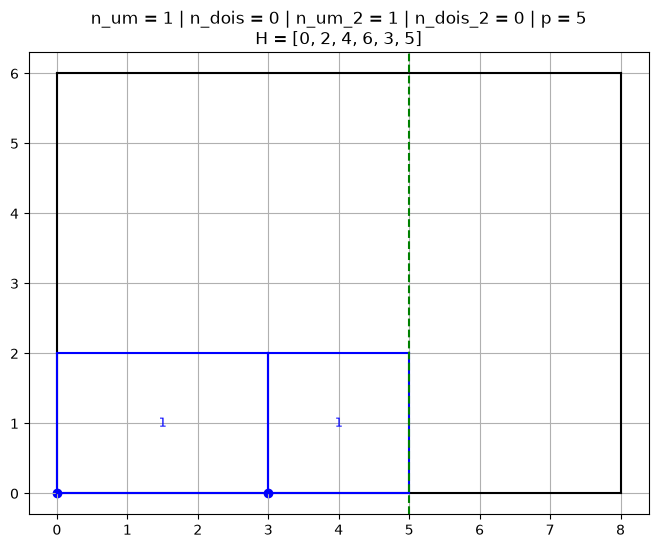

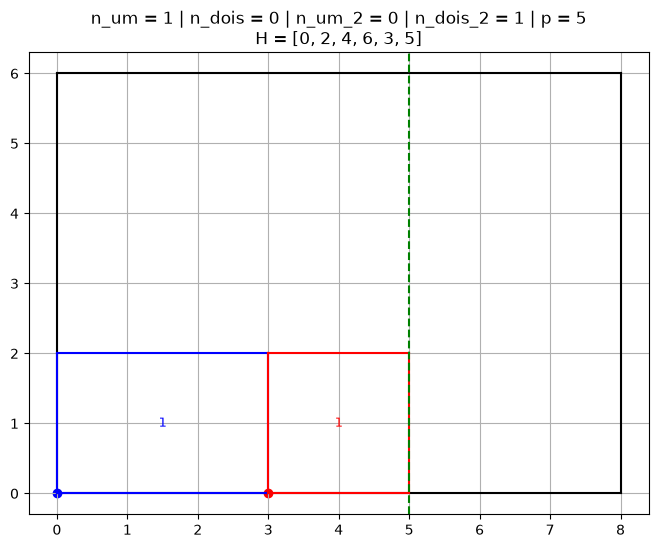

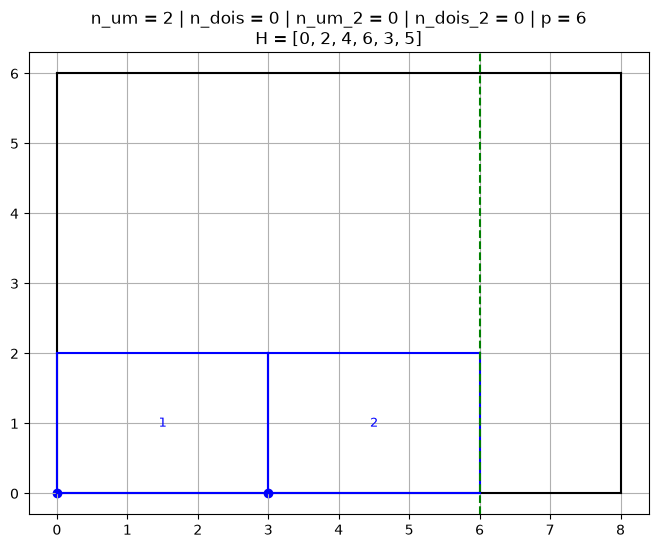

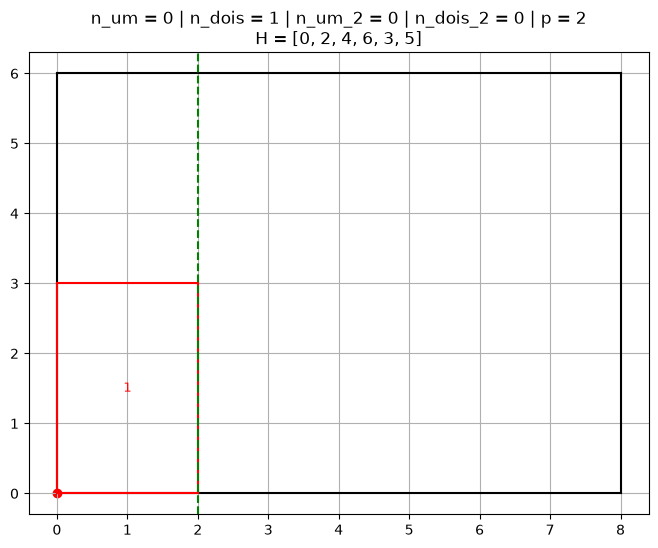

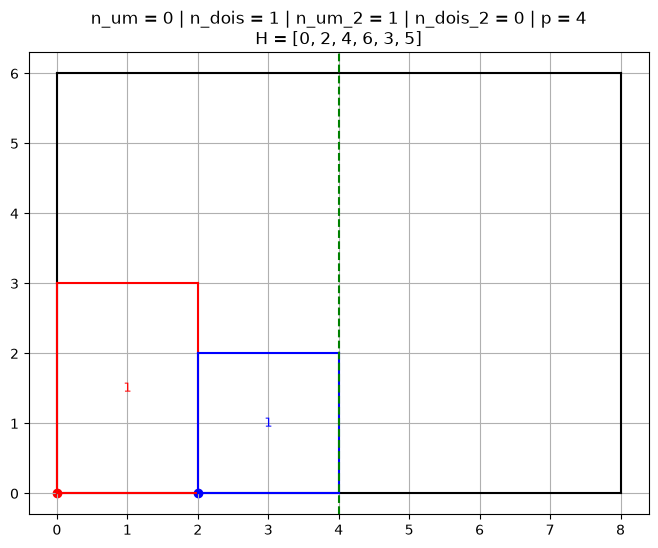

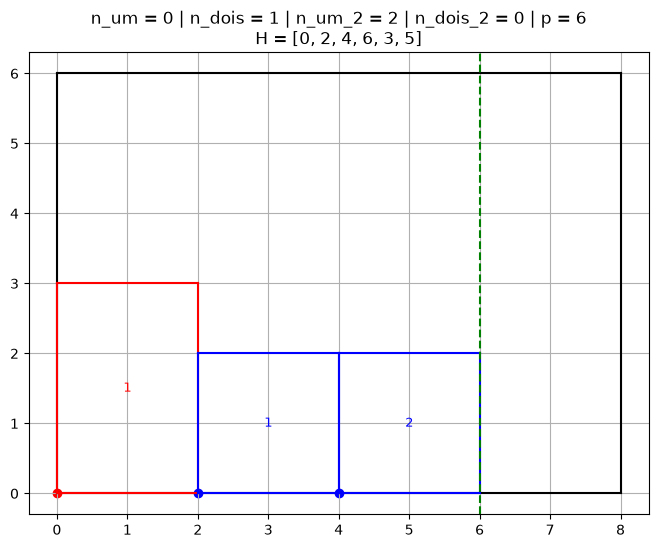

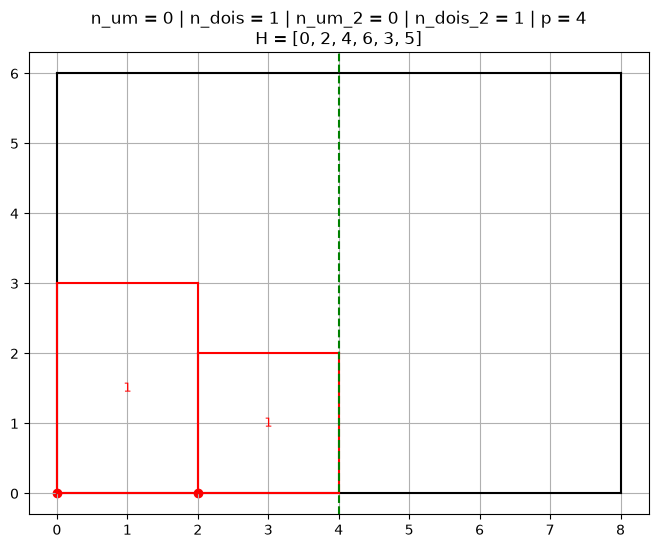

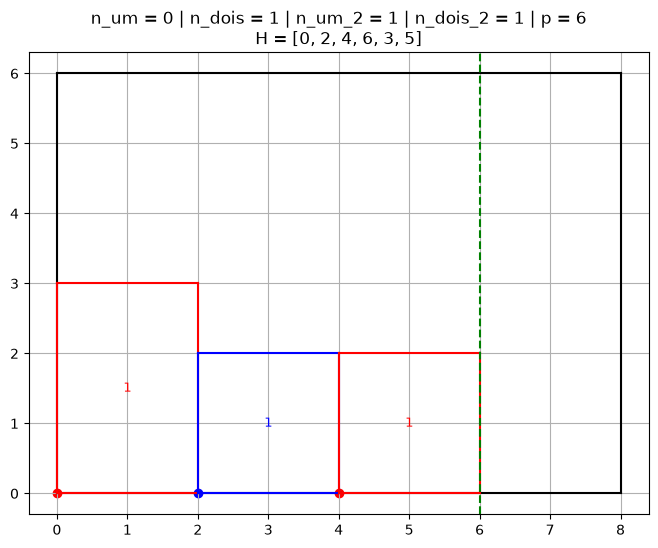

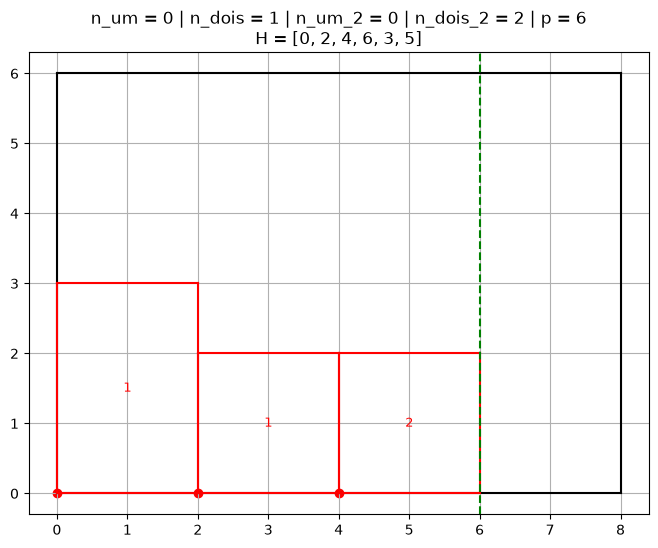

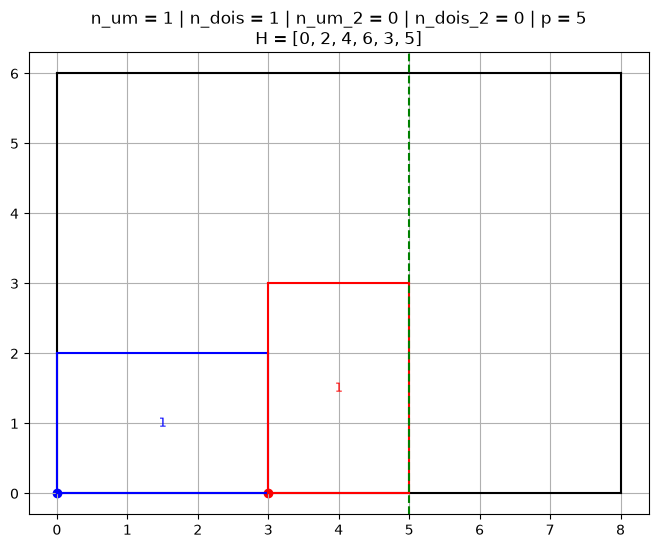

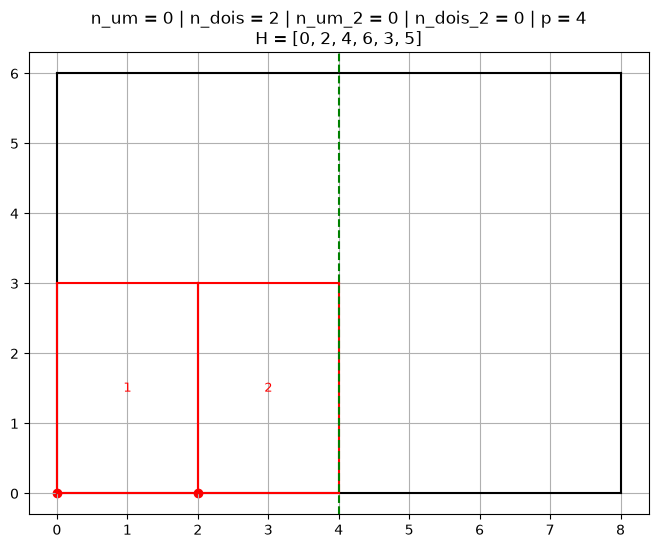

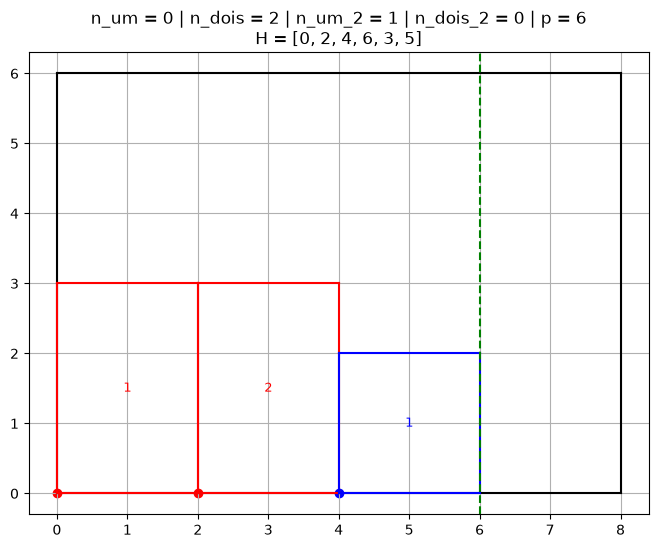

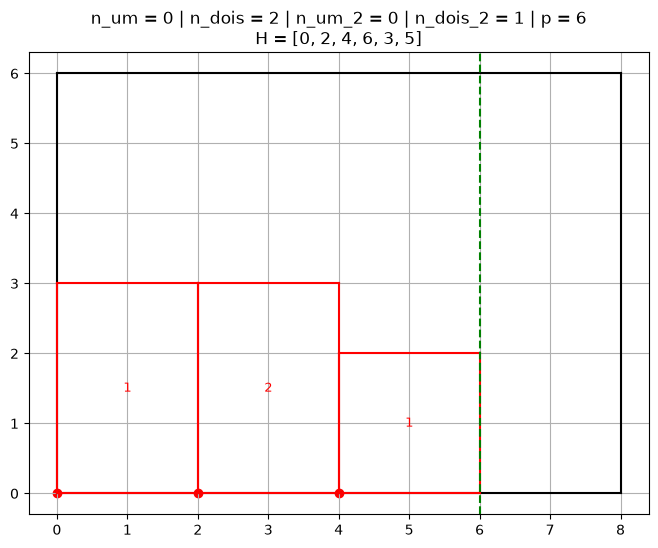

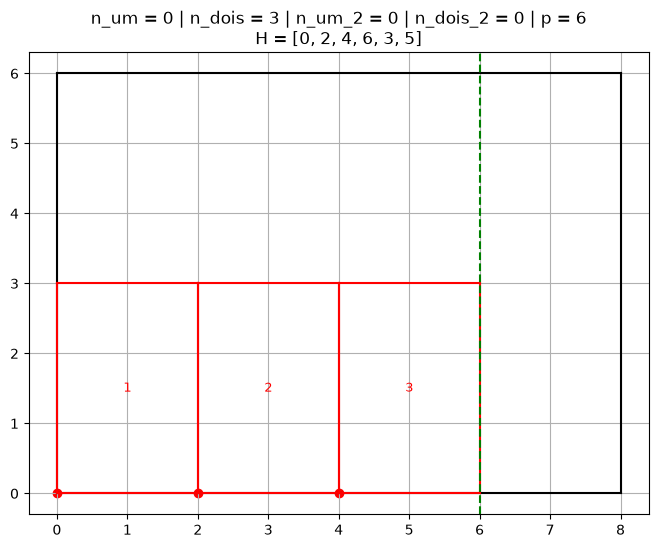

In [24]:
H = []
for n_dois, n_um, n_dois_2, n_um_2 in product(range(L), range(L), range(L), range(L)):  # variando o numero de caixas deitadas
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois, n_um_2, l_um_2, n_dois_2, l_dois_2)
    #print(n_um, n_dois, p)
    if p <= L - w_um and L - w_um_2:

        if p not in H:
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa_1(bottom_left=[n * l_um, 0], l=l_um, w=w_um, color="blue", label= n + 1)

        for n in range(n_dois):
            plotar_caixa_1(bottom_left=[n_um * l_um + n * l_dois, 0], l=l_dois, w=w_dois, color="red", label= n + 1)

        for n in range(n_um_2):
            plotar_caixa_2(bottom_left=[n * l_um_2  + n_um * l_um + n_dois * l_dois , 0], l=l_um_2, w=w_um_2, color="blue", label= n + 1)
        
        for n in range(n_dois_2):
            plotar_caixa_2(bottom_left=[n_um * l_um + n_dois * l_dois + n_um_2 * l_um_2 + n * l_dois_2, 0], l=l_dois_2, w=w_dois_2, color="red", label= n + 1)
        

        plt.axvline(x=p,color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {n_um_2 = } | {n_dois_2 = } | {p = }\n{H = }")
        plt.grid()

NameError: name 'plotar_caixa' is not defined

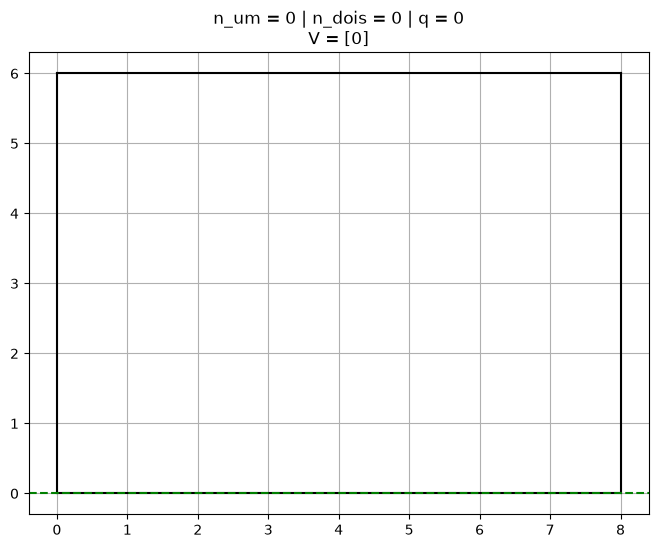

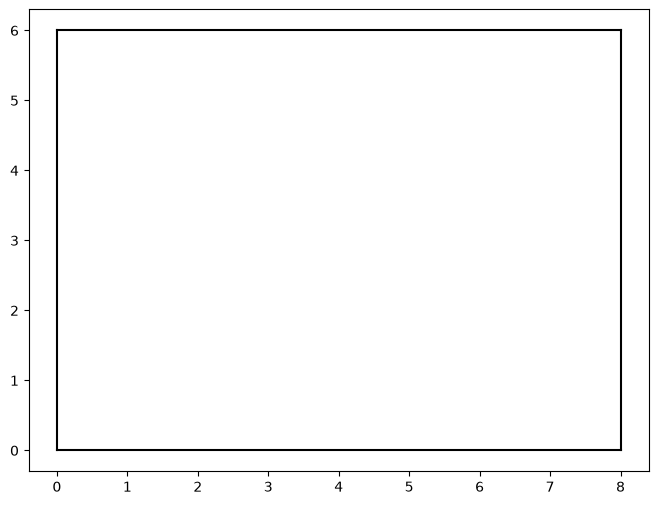

In [23]:
V = []
for n_dois, n_um in product(range(L), range(L)):  # variando o numero de caixas deitadas
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    #print(n_um, n_dois, p)
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n * w_um], l=l_um, w=w_um, color="blue", label= n + 1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * l_um + n * l_dois], l=l_dois, w=w_dois, color="red", label= n + 1)

        plt.axhline(y=q,color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")
        plt.grid()

In [ ]:
H = sorted(H)
V = sorted(V)

print(H)
print(V)

In [ ]:
lista_rs = list(product(H, V))
display(lista_rs)

In [ ]:
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color="purple")

    plt.title("Possibilidades de bottom left para as caixas")
    plt.grid()
    plt.show()

In [ ]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [ ]:
i = 1
print (ls[i-1], ws[i-1])

In [ ]:
lista_variaveis = []
plotar_palete(L, W)
for i, (p, q) in product([1, 2], lista_rs):
    # print(i, p, q)
    # i = 1 (caixa deitada)    
    # i = 2 (caixa em pé)
    if p + ls[i-1] <= L and q + ws [i-1] <= W: # checa se cabe no palete
        lista_variaveis.append((i, p, q))

        if indice == 0:
            cor = "blue" if i == 1 else "red"
            plt.scatter(x=p, y=q, color=cor) # plota o bottom left

            if i == 1:
                plt.text(x=p - 0.3, y=q + 0.15, s=f"({i}, {p}, {q})", color=cor, fontsize=10)

            else:
                plt.text(x=p - 0.3, y=q - 0.25, s=f"({i}, {p}, {q})", color=cor, fontsize=10)

In [ ]:
lista_variaveis

In [ ]:
print(len(lista_variaveis))

In [ ]:
prob = plp.LpProblem(name="Palete-Caixa", sense=plp.LpMaximize)
display(prob)

In [ ]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis, lowBound=0, upBound=1,
                                      cat=plp.LpBinary)

display(dict_variaveis)

In [ ]:
#dict_variaveis.values()
prob+= sum(dict_variaveis.values())
display(prob)

In [ ]:
print(f"Qtd variaveis: {prob.numVariables()}")
print(f"Qtd rstrições: {prob.numConstraints()}")

In [ ]:
def ponto_dentro_caixa(ponto_rs: tuple, ponto_pq: tuple, l: int, w: int) -> bool:
    r, s, = ponto_rs
    p, q = ponto_pq
    return p <=r < p + l and q <= s < q + w
print(ponto_dentro_caixa((6,2), (6,0), l=ls[0], w=ws[0]))

In [ ]:
plotar_palete(L,W)
r, s = lista_rs[9]
plt.scatter(x=r, y=s, color="green", s=100)
caixas_sobrepostas = []
for i, p, q in lista_variaveis:
    if ponto_dentro_caixa((r, s), (p, q), l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p, q), ls[i-1], ws[i-1], color="blue" if i == 1 else "red", label=f"{i, p, q}")

In [ ]:
#plotar_palete(L,W)
#r, s = lista_rs[9]
n = 0
for r, s in lista_rs:        
    #plt.scatter(x=r, y=s, color="green", s=100)
    caixas_sobrepostas = []
    for i, p, q in lista_variaveis:
        if ponto_dentro_caixa((r, s), (p, q), l=ls[i-1], w=ws[i-1]):
            #plotar_caixa((p, q), ls[i-1], ws[i-1], color="blue" if i == 1 else "red", label=f"{i, p, q}")
            caixas_sobrepostas.append(dict_variaveis[(i, p, q)])
    #print(sum(caixas_sobrepostas))
    prob += sum(caixas_sobrepostas) <= 1, f"Restrição 1.{n}"
    n += 1

In [ ]:
display(prob)

In [ ]:
print(prob.numVariables())
print(prob.numVariables())

In [ ]:
qts_maxima_caixas = (L * W) // (l_um * w_um)
print(qts_maxima_caixas)

In [ ]:
prob +=sum(dict_variaveis.values()) <= qts_maxima_caixas, "restrição_2."
display(prob)
           

In [ ]:
print(prob.numVariables())
print(prob.numConstraints())


In [ ]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)

In [ ]:
prob.solve(solver)

In [ ]:
display(plp.LpStatus)

In [ ]:
print(prob.variables())

In [ ]:
print(prob.variables()[0].name, prob.variables()[0].varValue)
print(prob.variables()[0].name, prob.variables()[2].varValue)
print(prob.objective.value())

In [ ]:
dict_traducao = \
    dict(zip(dict_variaveis.values(),
             dict_variaveis.keys()))
display(dict_traducao)

In [ ]:
variaveis_organizadas = []
for variavel in prob.variables():
    #print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [ ]:
from copy import deepcopy
solucoes = [deepcopy(variaveis_organizadas)]

In [ ]:
from random import random, seed
seed(42)

n = 0
for variavel in prob.variables():
    if variavel.varValue > 0:

        if random() > 0.2:
            continue

        # print(variavel)
        prob += variavel == 0, f"restrição_3.{n}"
        n += 1

display(prob)

In [ ]:
print(prob.numVariables())
print(prob.numConstraints())


In [ ]:
prob.solve(solver)

In [ ]:
variaveis_organizadas = []
for variavel in prob.variables():
    #print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [ ]:
solucoes.append(deepcopy(variaveis_organizadas))

In [ ]:
from matplotlib.figure import Figure
from matplotlib.axes import Axes
import numpy as np

fig: Figure
axes: np.ndarray[Axes]

fig, axes = plt.subplots(ncols=2, figsize=(20, 10))
fig.set_facecolor('#f4f4f4')

for idx, (ax, solucao) in enumerate(zip(axes, solucoes[:2]), start=1):
    ax.set_xticks(list(range(0, L + 1, l_um)) + [L])
    ax.set_yticks(list(range(0, W + 1, w_um)) + [W])
    ax.set_xlim(-1, L + 1)
    ax.set_ylim(-1, W + 1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

    # borda da palete
    for x0, y0, x1, y1 in [(0, 0, L, 0), (0, 0, 0, W), (0, W, L, W), (L, 0, L, W)]:
        ax.plot([x0, x1], [y0, y1], 'k-', lw=2)

    for n_caixa, (i, p, q) in enumerate(solucao, start=1):
        ax.add_patch(plt.Rectangle(
            xy=(p, q),
            width=ls[i - 1],
            height=ws[i - 1],
            facecolor="#4e4af1" if i == 1 else "#d16262",
            edgecolor="white",
            lw=1
        ))
        ax.text(
            p + ls[i - 1] / 2,
            q + ws[i - 1] / 2,
            str(n_caixa),
            ha="center",
            va="center",
            fontsize=14,
            color="#f4f4f4"
        )

    ax.set_title(f"Solução {idx}\nQuantidade de caixas: {len(solucao)}\nQuantidade Máxima: {qtd_caixas}", fontsize=18)

plt.tight_layout()
plt.show()